# Colab Session: ai301-head-fold0
Generated from colab-cli history log.

**Session Created**: 2026-10-17 09:36:01
- Endpoint: `gpu-t4-s-kkb-ass1c1-2n14ueqbni1mq`
- Hardware: `T4`

### Automation: install (2026-10-17 09:36:32)

In [ ]:

import subprocess, sys
def install():
    packages = ['timm>=1.0,<2', 'lightning>=2.5,<3', 'wandb>=0.19,<1', 'scikit-learn>=1.5,<2', 'matplotlib>=3.9,<4']
    try:
        subprocess.check_call(['uv', 'pip', 'install', '--system'] + packages)
        print('Installation Complete (via uv)!')
    except:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install'] + packages)
        print('Installation Complete (via pip)!')
install()


In [ ]:
# Result of previous automation

Installation Complete (via uv)!


*File Operation*: `upload` on `/content/folds.csv`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.000`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.001`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.002`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.003`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.004`

In [ ]:
import torch, timm, lightning, wandb, sklearn
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("Versions:", torch.__version__, timm.__version__, lightning.__version__, wandb.__version__, sklearn.__version__)


GPU: Tesla T4
Versions: 2.11.0+cu130 1.0.30 2.6.6 0.28.1 1.6.1


*File Operation*: `upload` on `/content/ai301-head-fold0.part.005`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.006`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.007`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.008`

*File Operation*: `upload` on `/content/05_convnext_head.ipynb`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.009`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.010`

*File Operation*: `upload` on `/content/ai301-head-wandb.env`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.011`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.012`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.013`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.014`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.015`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.016`

*File Operation*: `upload` on `/content/ai301-head-fold0.part.017`

*File Operation*: `upload` on `/content/05_convnext_head.ipynb`

In [ ]:
from pathlib import Path
import hashlib, shutil, subprocess
parts = sorted(Path("/content").glob("ai301-head-fold0.part.*"))
assert len(parts) == 18, f"Expected 18 chunks, found {len(parts)}"
subprocess.run(["bash", "-lc", "cat /content/ai301-head-fold0.part.* > /content/ai301-head-fold0.tar"], check=True)
archive = Path("/content/ai301-head-fold0.tar")
digest = hashlib.sha256(archive.read_bytes()).hexdigest()
assert digest == "55d40422bec2f6a23e21775e40ecc4f5885d8c0458f7dd36ce51a7330534cf3a", "Training archive checksum mismatch"
root = Path("/content/ai301")
root.mkdir(exist_ok=True)
subprocess.run(["tar", "-xf", str(archive), "-C", str(root)], check=True)
(root / "notebooks").mkdir(exist_ok=True)
shutil.move("/content/05_convnext_head.ipynb", root / "notebooks" / "05_convnext_head.ipynb")
shutil.move("/content/ai301-head-wandb.env", root / ".env")
(root / ".env").chmod(0o600)
print("Verified archive; train images:", len(list((root / "data" / "train").glob("*.jpg"))))
print("Secret file permission:", oct((root / ".env").stat().st_mode & 0o777))


Verified archive; train images: 24520
Secret file permission: 0o600


In [ ]:
print("Kernel is responding")


Kernel is responding


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
from __future__ import annotations

import hashlib
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'  # Partial batches; not a reportable result.
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists below.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_head_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0  # Portable starting point on macOS and Colab.

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}')

Device: cuda; training: False; smoke test: True


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities

DATA_DIR = ROOT / 'data'
combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
    raise ValueError('test.csv and sample_submission.csv have different image IDs.')
for row, directory in ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'), (test_rows[0], DATA_DIR / 'test')):
    if not (directory / f"{row['image_id']}.jpg").is_file():
        raise FileNotFoundError(f'Missing image in {directory}.')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

FileNotFoundError: Missing image in /content/ai301/data/test.

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B credential check skipped until online training is enabled.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
    preprocessing = timm.data.resolve_model_data_config(network)
    if preprocessing['input_size'][-1] != IMAGE_SIZE:
        raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
    freeze_except_classifier(network)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_loader = DataLoader(train_data, shuffle=True, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
else:
    print('Model loading skipped.')

Model loading skipped.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    module = MultilabelClassifier(network, LEARNING_RATE, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
    checkpoint = ModelCheckpoint(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    callbacks = [checkpoint]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        if WANDB_MODE not in {'offline', 'online'}:
            raise ValueError('WANDB_MODE must be offline or online.')
        from lightning.pytorch.loggers import WandbLogger
        wandb_logger = WandbLogger(
            project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir),
            offline=WANDB_MODE == 'offline', log_model=False,
        )
        wandb_logger.log_hyperparams({
            'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED,
            'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'weight_decay': WEIGHT_DECAY, 'threshold': THRESHOLD,
            'smoke_test': SMOKE_TEST, 'trainable_part': 'classifier',
        })
        wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
        print('W&B run:', wandb_logger.experiment.url)
        loggers.append(wandb_logger)
    trainer = L.Trainer(
        accelerator=DEVICE.type, devices=1, precision='32-true', max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
        accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
        limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
        num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
    )
    started = time.perf_counter()
    try:
        trainer.fit(module, train_loader, validation_loader)
    finally:
        if wandb_logger is not None:
            wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
else:
    print('No training or checkpoint write.')

No training or checkpoint write.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_epoch', 'gradient_norm_step')),
        ('Loss', 'Validation macro metrics', 'Gradient norm'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
else:
    print('No training curves to plot.')

No training curves to plot.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING and not SMOKE_TEST:
    if not checkpoint.best_model_path:
        raise RuntimeError('Training produced no best checkpoint.')
    best_module = MultilabelClassifier.load_from_checkpoint(
        checkpoint.best_model_path, network=network, learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY, threshold=THRESHOLD, frozen_backbone=True,
    )
    prediction_started = time.perf_counter()
    predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
    prediction_seconds = time.perf_counter() - prediction_started
    if predicted_ids != [row['image_id'] for row in validation_rows]:
        raise ValueError('Validation loader changed image order.')
    validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
    metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
    diagnostic_f1 = score_probabilities(validation_targets, validation_probabilities, 0.5)['macro_f1']
    print('Fold-0 metrics:', metrics)
    print('Macro F1 at 0.5:', round(diagnostic_f1, 5))
else:
    print('Full-fold evaluation skipped; smoke scores must not be reported.')

Full-fold evaluation skipped; smoke scores must not be reported.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING and not SMOKE_TEST:
    result_dir = ROOT / 'experiments' / '00_shared_head' / 'results'
    probability_path = result_dir / f'{RUN_ID}_val.csv'
    record_path = result_dir / f'{RUN_ID}.json'
    head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{RUN_ID}_head.pt'
    for path in (probability_path, record_path, head_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
    head_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(best_module.network.get_classifier().state_dict(), head_path)
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
    source_files = (ROOT / 'notebooks' / '05_convnext_head.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py')
    source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
    record = {
        'run_id': RUN_ID, 'experiment': '00_shared_head', 'status': 'completed', 'git_commit': git_commit, 'source_sha256': source_sha256,
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'head_only', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': None},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})', 'scheduler': 'constant', 'loss': 'BCEWithLogitsLoss', 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': 'float32', 'stage_policy': 'frozen backbone in eval mode; classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25'},
        'hardware': {'device': str(DEVICE), 'system_memory_gb': None},
        'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_f1},
        'timings': {'training_and_validation_seconds': training_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
        'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'head_checkpoint': str(head_path.relative_to(ROOT)), 'full_checkpoint_local': str(Path(checkpoint.best_model_path).relative_to(ROOT)), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT))},
        'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
        'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
        'public_leaderboard_score': None, 'error': None,
    }
    write_run_record(record_path, record)
    print('Saved:', record_path, probability_path, head_path, sep='\n')
else:
    print('No full-run artifacts written.')

No full-run artifacts written.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if BUILD_SUBMISSION:
    if not (RUN_TRAINING and not SMOKE_TEST):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_path = run_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


*File Operation*: `upload` on `/content/ai301/notebooks/05_convnext_head.ipynb`

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
from __future__ import annotations

import hashlib
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'  # Partial batches; not a reportable result.
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists below.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_head_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0  # Portable starting point on macOS and Colab.

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}')

Device: cuda; training: False; smoke test: True


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities

DATA_DIR = ROOT / 'data'
combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
    raise ValueError('test.csv and sample_submission.csv have different image IDs.')
required_images = ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'))
if BUILD_SUBMISSION:
    required_images += ((test_rows[0], DATA_DIR / 'test'),)
for row, directory in required_images:
    if not (directory / f"{row['image_id']}.jpg").is_file():
        raise FileNotFoundError(f'Missing image in {directory}.')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B credential check skipped until online training is enabled.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
    preprocessing = timm.data.resolve_model_data_config(network)
    if preprocessing['input_size'][-1] != IMAGE_SIZE:
        raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
    freeze_except_classifier(network)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_loader = DataLoader(train_data, shuffle=True, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
else:
    print('Model loading skipped.')

Model loading skipped.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    module = MultilabelClassifier(network, LEARNING_RATE, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
    checkpoint = ModelCheckpoint(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    callbacks = [checkpoint]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        if WANDB_MODE not in {'offline', 'online'}:
            raise ValueError('WANDB_MODE must be offline or online.')
        from lightning.pytorch.loggers import WandbLogger
        wandb_logger = WandbLogger(
            project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir),
            offline=WANDB_MODE == 'offline', log_model=False,
        )
        wandb_logger.log_hyperparams({
            'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED,
            'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'weight_decay': WEIGHT_DECAY, 'threshold': THRESHOLD,
            'smoke_test': SMOKE_TEST, 'trainable_part': 'classifier',
        })
        wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
        print('W&B run:', wandb_logger.experiment.url)
        loggers.append(wandb_logger)
    trainer = L.Trainer(
        accelerator=DEVICE.type, devices=1, precision='32-true', max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
        accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
        limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
        num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
    )
    started = time.perf_counter()
    try:
        trainer.fit(module, train_loader, validation_loader)
    finally:
        if wandb_logger is not None:
            wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
else:
    print('No training or checkpoint write.')

No training or checkpoint write.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_epoch', 'gradient_norm_step')),
        ('Loss', 'Validation macro metrics', 'Gradient norm'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
else:
    print('No training curves to plot.')

No training curves to plot.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING and not SMOKE_TEST:
    if not checkpoint.best_model_path:
        raise RuntimeError('Training produced no best checkpoint.')
    best_module = MultilabelClassifier.load_from_checkpoint(
        checkpoint.best_model_path, network=network, learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY, threshold=THRESHOLD, frozen_backbone=True,
    )
    prediction_started = time.perf_counter()
    predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
    prediction_seconds = time.perf_counter() - prediction_started
    if predicted_ids != [row['image_id'] for row in validation_rows]:
        raise ValueError('Validation loader changed image order.')
    validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
    metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
    diagnostic_f1 = score_probabilities(validation_targets, validation_probabilities, 0.5)['macro_f1']
    print('Fold-0 metrics:', metrics)
    print('Macro F1 at 0.5:', round(diagnostic_f1, 5))
else:
    print('Full-fold evaluation skipped; smoke scores must not be reported.')

Full-fold evaluation skipped; smoke scores must not be reported.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if RUN_TRAINING and not SMOKE_TEST:
    result_dir = ROOT / 'experiments' / '00_shared_head' / 'results'
    probability_path = result_dir / f'{RUN_ID}_val.csv'
    record_path = result_dir / f'{RUN_ID}.json'
    head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{RUN_ID}_head.pt'
    for path in (probability_path, record_path, head_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
    head_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(best_module.network.get_classifier().state_dict(), head_path)
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
    source_files = (ROOT / 'notebooks' / '05_convnext_head.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py')
    source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
    record = {
        'run_id': RUN_ID, 'experiment': '00_shared_head', 'status': 'completed', 'git_commit': git_commit, 'source_sha256': source_sha256,
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'head_only', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': None},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})', 'scheduler': 'constant', 'loss': 'BCEWithLogitsLoss', 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': 'float32', 'stage_policy': 'frozen backbone in eval mode; classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25'},
        'hardware': {'device': str(DEVICE), 'system_memory_gb': None},
        'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_f1},
        'timings': {'training_and_validation_seconds': training_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
        'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'head_checkpoint': str(head_path.relative_to(ROOT)), 'full_checkpoint_local': str(Path(checkpoint.best_model_path).relative_to(ROOT)), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT))},
        'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
        'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
        'public_leaderboard_score': None, 'error': None,
    }
    write_run_record(record_path, record)
    print('Saved:', record_path, probability_path, head_path, sep='\n')
else:
    print('No full-run artifacts written.')

No full-run artifacts written.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
if BUILD_SUBMISSION:
    if not (RUN_TRAINING and not SMOKE_TEST):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_path = run_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
from __future__ import annotations

import hashlib
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'  # Partial batches; not a reportable result.
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists below.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_head_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0  # Portable starting point on macOS and Colab.

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}')

Device: cuda; training: True; smoke test: True


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities

DATA_DIR = ROOT / 'data'
combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
    raise ValueError('test.csv and sample_submission.csv have different image IDs.')
required_images = ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'))
if BUILD_SUBMISSION:
    required_images += ((test_rows[0], DATA_DIR / 'test'),)
for row, directory in required_images:
    if not (directory / f"{row['image_id']}.jpg").is_file():
        raise FileNotFoundError(f'Missing image in {directory}.')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B credential check skipped until online training is enabled.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if RUN_TRAINING:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
    preprocessing = timm.data.resolve_model_data_config(network)
    if preprocessing['input_size'][-1] != IMAGE_SIZE:
        raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
    freeze_except_classifier(network)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_loader = DataLoader(train_data, shuffle=True, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
else:
    print('Model loading skipped.')

INFO: Seed set to 42


INFO:lightning.fabric.utilities.seed:Seed set to 42


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
Trainable parameters: 5125


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if RUN_TRAINING:
    run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    module = MultilabelClassifier(network, LEARNING_RATE, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
    checkpoint = ModelCheckpoint(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    callbacks = [checkpoint]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        if WANDB_MODE not in {'offline', 'online'}:
            raise ValueError('WANDB_MODE must be offline or online.')
        from lightning.pytorch.loggers import WandbLogger
        wandb_logger = WandbLogger(
            project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir),
            offline=WANDB_MODE == 'offline', log_model=False,
        )
        wandb_logger.log_hyperparams({
            'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED,
            'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'weight_decay': WEIGHT_DECAY, 'threshold': THRESHOLD,
            'smoke_test': SMOKE_TEST, 'trainable_part': 'classifier',
        })
        wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
        print('W&B run:', wandb_logger.experiment.url)
        loggers.append(wandb_logger)
    trainer = L.Trainer(
        accelerator=DEVICE.type, devices=1, precision='32-true', max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
        accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
        limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
        num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
    )
    started = time.perf_counter()
    try:
        trainer.fit(module, train_loader, validation_loader)
    finally:
        if wandb_logger is not None:
            wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
else:
    print('No training or checkpoint write.')

Epoch 0/0  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 0:00:03 • 0:00:00 9.64it/s v_num: 0.000 val_macro_f1: 0.253    
                                                                               train_loss: 0.764                   

INFO: `Trainer.fit` stopped: `max_epochs=1` reached.


INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.


Training and validation: 0.1 min; best: /content/ai301/artifacts/convnext_head_fold0_colab_probe_smoke/checkpoints/best.ckpt


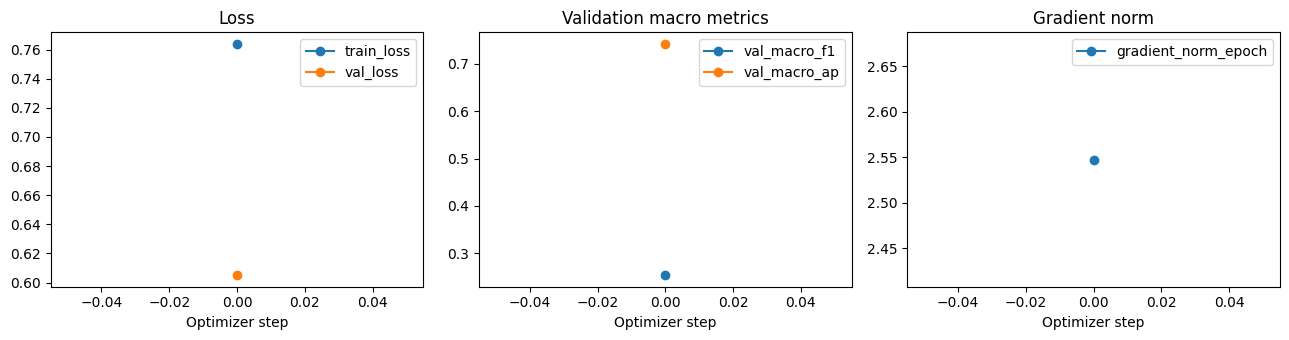

Saved curves: /content/ai301/artifacts/convnext_head_fold0_colab_probe_smoke/curves.png


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_epoch', 'gradient_norm_step')),
        ('Loss', 'Validation macro metrics', 'Gradient norm'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
else:
    print('No training curves to plot.')

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if RUN_TRAINING and not SMOKE_TEST:
    if not checkpoint.best_model_path:
        raise RuntimeError('Training produced no best checkpoint.')
    best_module = MultilabelClassifier.load_from_checkpoint(
        checkpoint.best_model_path, network=network, learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY, threshold=THRESHOLD, frozen_backbone=True,
    )
    prediction_started = time.perf_counter()
    predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
    prediction_seconds = time.perf_counter() - prediction_started
    if predicted_ids != [row['image_id'] for row in validation_rows]:
        raise ValueError('Validation loader changed image order.')
    validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
    metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
    diagnostic_f1 = score_probabilities(validation_targets, validation_probabilities, 0.5)['macro_f1']
    print('Fold-0 metrics:', metrics)
    print('Macro F1 at 0.5:', round(diagnostic_f1, 5))
else:
    print('Full-fold evaluation skipped; smoke scores must not be reported.')

Full-fold evaluation skipped; smoke scores must not be reported.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if RUN_TRAINING and not SMOKE_TEST:
    result_dir = ROOT / 'experiments' / '00_shared_head' / 'results'
    probability_path = result_dir / f'{RUN_ID}_val.csv'
    record_path = result_dir / f'{RUN_ID}.json'
    head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{RUN_ID}_head.pt'
    for path in (probability_path, record_path, head_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
    head_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(best_module.network.get_classifier().state_dict(), head_path)
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
    source_files = (ROOT / 'notebooks' / '05_convnext_head.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py')
    source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
    record = {
        'run_id': RUN_ID, 'experiment': '00_shared_head', 'status': 'completed', 'git_commit': git_commit, 'source_sha256': source_sha256,
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'head_only', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': None},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})', 'scheduler': 'constant', 'loss': 'BCEWithLogitsLoss', 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': 'float32', 'stage_policy': 'frozen backbone in eval mode; classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25'},
        'hardware': {'device': str(DEVICE), 'system_memory_gb': None},
        'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_f1},
        'timings': {'training_and_validation_seconds': training_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
        'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'head_checkpoint': str(head_path.relative_to(ROOT)), 'full_checkpoint_local': str(Path(checkpoint.best_model_path).relative_to(ROOT)), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT))},
        'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
        'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
        'public_leaderboard_score': None, 'error': None,
    }
    write_run_record(record_path, record)
    print('Saved:', record_path, probability_path, head_path, sep='\n')
else:
    print('No full-run artifacts written.')

No full-run artifacts written.


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '1'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_USE_WANDB'] = '0'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_colab_probe'
if BUILD_SUBMISSION:
    if not (RUN_TRAINING and not SMOKE_TEST):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_path = run_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


*File Operation*: `upload` on `/content/ai301/notebooks/05_convnext_head.ipynb`

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
from __future__ import annotations

import hashlib
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'  # Partial batches; not a reportable result.
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists below.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_head_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0  # Portable starting point on macOS and Colab.

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}')

Device: cuda; training: True; smoke test: False


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities

DATA_DIR = ROOT / 'data'
combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
    raise ValueError('test.csv and sample_submission.csv have different image IDs.')
required_images = ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'))
if BUILD_SUBMISSION:
    required_images += ((test_rows[0], DATA_DIR / 'test'),)
for row, directory in required_images:
    if not (directory / f"{row['image_id']}.jpg").is_file():
        raise FileNotFoundError(f'Missing image in {directory}.')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
            env_file.unlink()
            print('Removed the temporary Colab credential file.')
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

Removed the temporary Colab credential file.
W&B online credential is available (value hidden).


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if RUN_TRAINING:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
    preprocessing = timm.data.resolve_model_data_config(network)
    if preprocessing['input_size'][-1] != IMAGE_SIZE:
        raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
    freeze_except_classifier(network)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_loader = DataLoader(train_data, shuffle=True, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
else:
    print('Model loading skipped.')

INFO: Seed set to 42


INFO:lightning.fabric.utilities.seed:Seed set to 42


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
Trainable parameters: 5125


*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves/version_0/metrics.csv`

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if RUN_TRAINING:
    run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    module = MultilabelClassifier(network, LEARNING_RATE, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
    checkpoint = ModelCheckpoint(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    callbacks = [checkpoint]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        if WANDB_MODE not in {'offline', 'online'}:
            raise ValueError('WANDB_MODE must be offline or online.')
        from lightning.pytorch.loggers import WandbLogger
        wandb_logger = WandbLogger(
            project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir),
            offline=WANDB_MODE == 'offline', log_model=False,
        )
        wandb_logger.log_hyperparams({
            'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED,
            'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'weight_decay': WEIGHT_DECAY, 'threshold': THRESHOLD,
            'smoke_test': SMOKE_TEST, 'trainable_part': 'classifier',
        })
        wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
        print('W&B run:', wandb_logger.experiment.url)
        loggers.append(wandb_logger)
    trainer = L.Trainer(
        accelerator=DEVICE.type, devices=1, precision='32-true', max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
        accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
        limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
        num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
    )
    started = time.perf_counter()
    try:
        trainer.fit(module, train_loader, validation_loader)
    finally:
        if wandb_logger is not None:
            wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
else:
    print('No training or checkpoint write.')

Epoch 9/9  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4904/4904 0:07:11 • 0:00:00 11.40it/s v_num: 8869 val_macro_f1: 0.933  
                                                                                  train_loss: 0.000                

INFO: `Trainer.fit` stopped: `max_epochs=10` reached.


INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


epoch,▁▁▁▁▁▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇█████
gradient_norm_epoch,█▃▂▂▂▁▁▁▁▁
gradient_norm_step,█▅▃▂▆▂▁▃▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▂▂▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▁▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇█████
val_f1_biatrix,▁▄████████
val_f1_cat,██▁▄▁▄▁▁▁▁
val_f1_dog,▁▅█▆▆▆▆█▆█
val_f1_moris,▁▅▇▇▇▇▇▇▇█
val_f1_motya,▃▁▅▅▇▇█▇▇▇
+3,...


Training and validation: 92.0 min; best: /content/ai301/artifacts/convnext_head_fold0_seed42_colab/checkpoints/best.ckpt


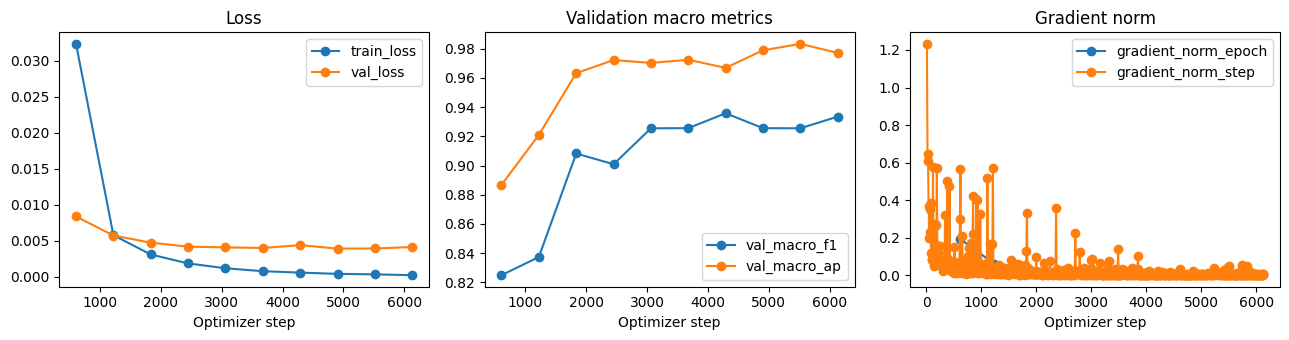

Saved curves: /content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves.png


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_epoch', 'gradient_norm_step')),
        ('Loss', 'Validation macro metrics', 'Gradient norm'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
else:
    print('No training curves to plot.')

In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if RUN_TRAINING and not SMOKE_TEST:
    if not checkpoint.best_model_path:
        raise RuntimeError('Training produced no best checkpoint.')
    best_module = MultilabelClassifier.load_from_checkpoint(
        checkpoint.best_model_path, network=network, learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY, threshold=THRESHOLD, frozen_backbone=True,
    )
    prediction_started = time.perf_counter()
    predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
    prediction_seconds = time.perf_counter() - prediction_started
    if predicted_ids != [row['image_id'] for row in validation_rows]:
        raise ValueError('Validation loader changed image order.')
    validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
    metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
    diagnostic_f1 = score_probabilities(validation_targets, validation_probabilities, 0.5)['macro_f1']
    print('Fold-0 metrics:', metrics)
    print('Macro F1 at 0.5:', round(diagnostic_f1, 5))
else:
    print('Full-fold evaluation skipped; smoke scores must not be reported.')

Fold-0 metrics: {'threshold': 0.25, 'macro_f1': 0.9357660566317454, 'per_label_f1': {'Cat': 0.9955773955773956, 'Dog': 0.9975111996017919, 'Moris': 0.8695652173913043, 'Motya': 0.875, 'Biatrix': 0.9411764705882353}, 'macro_ap': 0.9668250618913227, 'per_label_ap': {'Cat': 0.9999788420709081, 'Dog': 0.9999473331865711, 'Moris': 0.9651515151515151, 'Motya': 0.8690476190476193, 'Biatrix': 1.0}}
Macro F1 at 0.5: 0.91828


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if RUN_TRAINING and not SMOKE_TEST:
    result_dir = ROOT / 'experiments' / '00_shared_head' / 'results'
    probability_path = result_dir / f'{RUN_ID}_val.csv'
    record_path = result_dir / f'{RUN_ID}.json'
    head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{RUN_ID}_head.pt'
    for path in (probability_path, record_path, head_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
    head_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(best_module.network.get_classifier().state_dict(), head_path)
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
    source_files = (ROOT / 'notebooks' / '05_convnext_head.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py')
    source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
    record = {
        'run_id': RUN_ID, 'experiment': '00_shared_head', 'status': 'completed', 'git_commit': git_commit, 'source_sha256': source_sha256,
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'head_only', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': None},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})', 'scheduler': 'constant', 'loss': 'BCEWithLogitsLoss', 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': 'float32', 'stage_policy': 'frozen backbone in eval mode; classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25'},
        'hardware': {'device': str(DEVICE), 'system_memory_gb': None},
        'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_f1},
        'timings': {'training_and_validation_seconds': training_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
        'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'head_checkpoint': str(head_path.relative_to(ROOT)), 'full_checkpoint_local': str(Path(checkpoint.best_model_path).relative_to(ROOT)), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT))},
        'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
        'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
        'public_leaderboard_score': None, 'error': None,
    }
    write_run_record(record_path, record)
    print('Saved:', record_path, probability_path, head_path, sep='\n')
else:
    print('No full-run artifacts written.')

Saved:
/content/ai301/experiments/00_shared_head/results/convnext_head_fold0_seed42_colab.json
/content/ai301/experiments/00_shared_head/results/convnext_head_fold0_seed42_colab_val.csv
/content/ai301/experiments/00_shared_head/checkpoints/convnext_head_fold0_seed42_colab_head.pt


In [ ]:
import os
os.environ['STAGE2_ROOT'] = '/content/ai301'
os.environ['STAGE2_RUN_TRAINING'] = '1'
os.environ['STAGE2_SMOKE_TEST'] = '0'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_RUN_ID'] = 'convnext_head_fold0_seed42_colab'
os.environ['STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD'] = '1'
if BUILD_SUBMISSION:
    if not (RUN_TRAINING and not SMOKE_TEST):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_path = run_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


*File Operation*: `ls` on `/content/ai301/experiments/00_shared_head/results`

*File Operation*: `download` on `/content/ai301/experiments/00_shared_head/results/convnext_head_fold0_seed42_colab.json`

*File Operation*: `download` on `/content/ai301/experiments/00_shared_head/checkpoints/convnext_head_fold0_seed42_colab_head.pt`

*File Operation*: `download` on `/content/ai301/artifacts/convnext_head_fold0_seed42_colab/curves.png`

*File Operation*: `download` on `/content/ai301/experiments/00_shared_head/results/convnext_head_fold0_seed42_colab_val.csv`